### Import relevant libraries 

In [2]:
# %%
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2

In [3]:
# %%
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # Step 1: Generate Latin Hypercube Samples
    seed
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

# %%

### LHS sample for the 0th round

In [4]:
# %%
df_lhs = pd.DataFrame(latin_hypercube_sum_constraint(n_samples=8, n_variables=3, sum_constraint=270.0,seed=np.random.seed(2)),columns=['C','M','Y'])
df_lhs
# %%
df_lhs.to_numpy().T

array([[ 66.2929194 ,  45.138036  ,  92.95558656, 123.51430302,
         49.93562369, 249.061465  , 101.0333909 ,  12.80322339],
       [118.79327543, 113.87746066,  72.52169339, 106.28347106,
         59.32688198,   0.94313405,  34.70838084, 218.13078337],
       [ 84.91380517, 110.98450335, 104.52272005,  40.20222592,
        160.73749433,  19.99540095, 134.25822826,  39.06599324]])

### Data extraction
- After Mara has made the colors, extract the color data from the image


In [5]:
def load_image(image_path):
    # Load and convert the image to RGB if not already in that mode
    image = Image.open(image_path).convert("RGB")
    return image
def display_image_with_pixel_value(image_path, x, y):
    # Load the image
    image = load_image(image_path)
    # Convert image to array for display purposes
    image_array = np.array(image)
    # Get the RGB value at the selected coordinates
    rgb_value = image.getpixel((x, y))
    # Create a copy of the image to draw the red dot
    draw = ImageDraw.Draw(image)
    dot_radius = 5
    draw.ellipse((x - dot_radius, y - dot_radius, x + dot_radius, y + dot_radius), fill='red', outline='red')
    # Display the image with the red dot
    plt.figure(figsize=(6,6))  # Optional: Set figure size
    plt.imshow(image)
    plt.axis('on')
    plt.title(f'RGB value at ({x}, {y}): {rgb_value}')
# Load the image and get dimensions
image_path = 'IMG_2730.jpg'
image = load_image(image_path)
width, height = image.size
# Create interactive sliders for x and y coordinates
interact(display_image_with_pixel_value,
         image_path=fixed(image_path),
         x=IntSlider(min=0, max=width-1, step=1, value=width//2),
         y=IntSlider(min=0, max=height-1, step=1, value=height//2))

interactive(children=(IntSlider(value=1140, description='x', max=2279), IntSlider(value=975, description='y', …

<function __main__.display_image_with_pixel_value(image_path, x, y)>

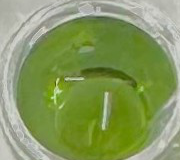

In [6]:
# Load the image
image_path = 'IMG_2730.jpg'
image = Image.open(image_path)


width, height = image.size

# Convert the image to RGB format
rgb_image = load_image('IMG_2730.jpg').convert('RGB')

# Define the region (x1, y1, x2, y2)
# (x1, y1) is the top-left corner, (x2, y2) is the bottom-right corner
region = (320, 125, 500, 285)  # Example coordinates for the region

# Crop the selected region
cropped_region = rgb_image.crop(region)

ydiff = 100

region2 = (320, 125, 500, 275)
cropped_region2 = rgb_image.crop(region)
# Convert the cropped region to a NumPy array
#region_np = np.array(cropped_region)

# Get the RGB values
# The shape of region_np will be (height, width, 3), where 3 represents the RGB channels
#rgb_values = region_np.reshape(-1, 3)

# Print the RGB values
cropped_region

# CV RGB Data Extraction

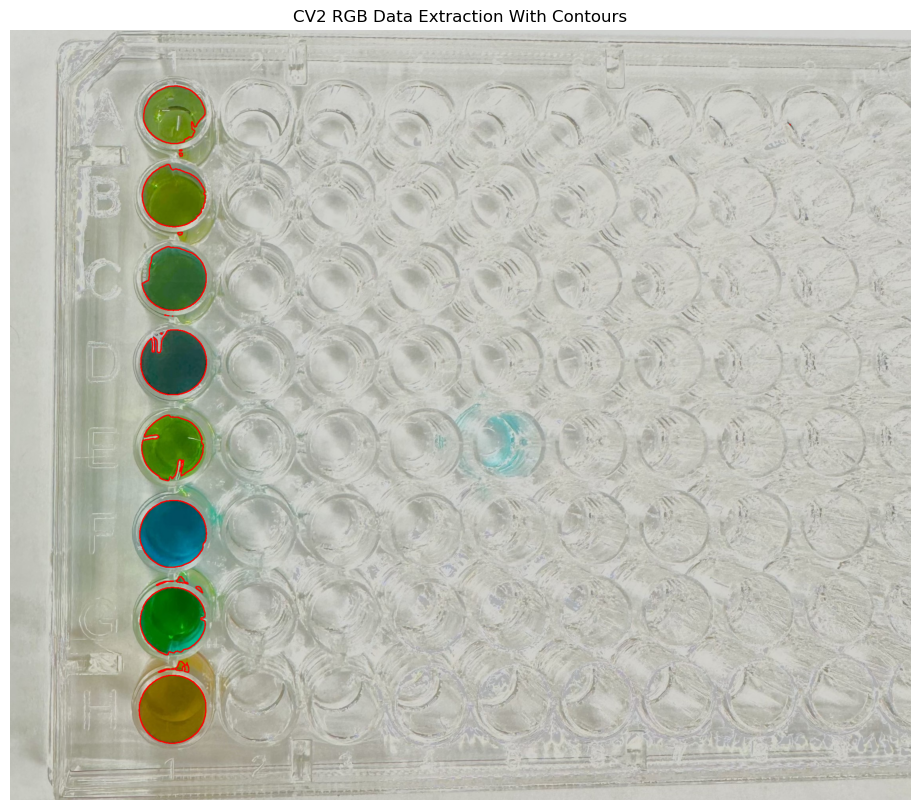

In [9]:
# Load the image

image = cv2.imread('IMG_2730.jpg', cv2.IMREAD_GRAYSCALE)
image = cv2.bilateralFilter(image,9,75,75)
image_rgb = cv2.imread('IMG_2730.jpg')

# Apply thresholding to isolate wells
ret, thresh = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)

# Find contours of the wells
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Helper function to get the centroid y-coordinate of a contour
def get_contour_y(contour):
    M = cv2.moments(contour)
    if M["m00"] != 0:
        return int(M["m01"] / M["m00"])  # Y-coordinate of the centroid
    return 0

# Sort contours by their y-coordinate
contours_ordered = sorted(contours, key=get_contour_y)

contour_plot = []
rgb_values = []

# Iterate through each detected contour
for contour in contours_ordered:
    #if cv2.contourArea(contour) < 10000:
    #    continue  # Skip small contours

    contour_plot.append(contour)

    # Create a mask for the current well
    mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
    cv2.drawContours(mask, [contour], -1, 255, -1)

    # Extract the ROI (well) using the mask
    well_pixels = cv2.bitwise_and(image_rgb, image_rgb, mask=mask)
    
    # Calculate the average BGR values
    mean_val = cv2.mean(image_rgb, mask=mask)[:3]
    rgb_values.append(mean_val[::-1]) # Reverse BGR output to RGB

output_image = image_rgb.copy()
cv2.drawContours(output_image, contour_plot, -1, (0, 0, 255), 2)
output_image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)  # Convert to RGB for matplotlib

# Double check contours
plt.figure(figsize=(12,10))
plt.imshow(output_image_rgb)
plt.axis('off')  # Hide axis
plt.title('CV2 RGB Data Extraction With Contours')
plt.show()

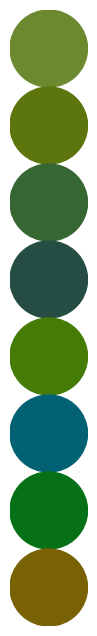

In [8]:
# Create a figure and axis
fig, ax = plt.subplots(figsize=(1, 8))

# Number of colors
num_colors = len(rgb_values)

# Create a circle for each color
for i, rgb in enumerate(rgb_values):
    color = [val / 255 for val in rgb]  # Normalize RGB values to [0, 1] range
    circle = plt.Circle((0.5, num_colors - i - 0.5), 0.5, color=color)
    ax.add_patch(circle)

# Set the limits and remove axes
ax.set_xlim(0, 1)
ax.set_ylim(0, num_colors)
ax.axis('off')

# Display the plot
plt.show()